# 04 — The official register, and what rents did

Two official sources next to the Airbnb data:

- **Barcelona's register of tourist flats (HUT)** — Ajuntament open data,
  quarterly. It is the legal count of licences, which Airbnb listings are not.
  Its **records** (case ids) and its **licence numbers** are different units: a
  few records have no usable number.
- **Average rent of new leases** — Generalitat de Catalunya (Incasòl
  deposits), quarterly, Barcelona as a whole.

**Privacy:** the register lists each flat down to floor and door. This
notebook only ever shows counts; `src/official.py` never returns addresses.

**Population:** Airbnb listings with open dates, as on the website.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning, metrics, official
from src import sources as src

sns.set_theme(style="whitegrid", palette="colorblind")
LATEST_QUARTER = list(src.HUT_REGISTER_URLS)[-1]

snapshots = {date: cleaning.add_columns(cleaning.load_snapshot("barcelona", date))
             for date in src.SNAPSHOTS["barcelona"]}

## How many licences exist?

In [2]:
official.hut_totals().to_frame()

,registered_huts
2025_1T,10514
2025_2T,10569
2025_3T,10688
2025_4T,10723
2026_1T,10730
2026_3T,10721


About 10,700 records, flat through 2025–2026. The register does not shrink
ahead of the 2028 deadline of Decret llei 3/2023, and a stable register before a
deadline says nothing about whether the policy will work.

## Do the licence numbers on Airbnb exist in the register?

Each listing's HUT number (regional section only — see
`cleaning.listing_hut_number`) is matched against the register quarter
**nearest in time** to the snapshot (`official.register_quarter_for`; 2026 Q2 is
not published, so the June snapshot uses Q1). Only counts are reported.

A match shows that a number *exists* in the register. It does not show that the
listing is that property, and it cannot show how many licensed flats are absent
from Airbnb.

In [3]:
rows = []
for date, df in snapshots.items():
    quarter = official.register_quarter_for(date)
    numbers = official.registered_hut_numbers(quarter)
    shown = metrics.active(df)["license"].map(cleaning.listing_hut_number).dropna()
    rows.append({
        "snapshot": date,
        "register_quarter": quarter,
        "register_records": official.register_record_count(quarter),
        "register_numbers": len(numbers),
        **official.summarise_match(shown, numbers),
    })
match = pd.DataFrame(rows).set_index("snapshot")
match

,register_quarter,register_records,register_numbers,listings_showing_number,displayed_numbers,displayed_numbers_found_in_register,displayed_found_pct,register_numbers_displayed_pct,numbers_on_2plus_listings
snapshot,,,,,,,,,
2025-12-14,2025_4T,10723,10625,5613,4711,3932,83.5,37.0,427
2026-03-21,2026_1T,10730,10630,6357,5417,4580,84.5,43.1,473
2026-06-24,2026_1T,10730,10630,7146,6116,5177,84.6,48.7,524
2026-09-17,2026_3T,10721,10623,5330,4715,4056,86.0,38.2,329


Three readings, each with its limit:

1. **83–86% of the numbers displayed on listings with open dates exist in the
   register** (`displayed_found_pct`). The rest can be typos, licences issued
   or cancelled between the two dates, or numbers that do not belong to the
   listing. The file cannot tell these apart, so the unmatched share is *not*
   a count of illegal listings.
2. **37–49% of the register's numbers are displayed on at least one such
   listing** (`register_numbers_displayed_pct`). This is *displayed-number
   coverage*, not "the share of licensed flats on Airbnb": a number can be
   shown by a listing that is not that flat, and a flat can be listed without
   its number. The denominator is register *numbers*, not records.
3. **A few hundred numbers appear on two or more listings.** One flat can be
   advertised more than once (for example with different minimum stays), so
   this is not evidence of a shared or borrowed licence by itself.

## Where are licences, and where are listings?

Per neighbourhood: registered flats (official) against Airbnb listings with
open dates showing a tourist-flat licence. The 5 register records with no known
neighbourhood are left out of the chart and counted in the totals above.

In [4]:
latest = metrics.active(snapshots[src.SNAPSHOTS["barcelona"][-1]])
key = latest["neighbourhood"].map(official.normalise_place_name)

by_place = pd.DataFrame({
    "district": latest.groupby(key)["neighbourhood_group"].first(),
    "active_listings": latest.groupby(key)["id"].count(),
    "listings_with_licence": latest.groupby(key)["has_tourist_licence"].sum(),
}).join(official.hut_counts_by_neighbourhood(LATEST_QUARTER), how="outer").fillna(
    {"active_listings": 0, "listings_with_licence": 0, "registered_huts": 0})
by_place = by_place.drop(index="nan", errors="ignore")   # register records with no neighbourhood

rho, p_value = stats.spearmanr(by_place["registered_huts"], by_place["listings_with_licence"])
print(f"{len(by_place)} neighbourhoods, Spearman rho = {rho:.2f} (p = {p_value:.1e})")
by_place.sort_values("registered_huts", ascending=False).head(10)

69 neighbourhoods, Spearman rho = 0.97 (p = 2.1e-43)


,district,active_listings,listings_with_licence,registered_huts
neighbourhood,,,,
la dreta de l'eixample,Eixample,1658.0,792.0,1786.0
la sagrada família,Eixample,702.0,425.0,825.0
la vila de gràcia,Gràcia,719.0,361.0,805.0
l'antiga esquerra de l'eixample,Eixample,698.0,341.0,726.0
sant antoni,Eixample,600.0,346.0,669.0
el poble sec,Sants-Montjuïc,580.0,394.0,574.0
la nova esquerra de l'eixample,Eixample,457.0,243.0,510.0
el poblenou,Sant Martí,310.0,153.0,459.0
el fort pienc,Eixample,348.0,213.0,381.0


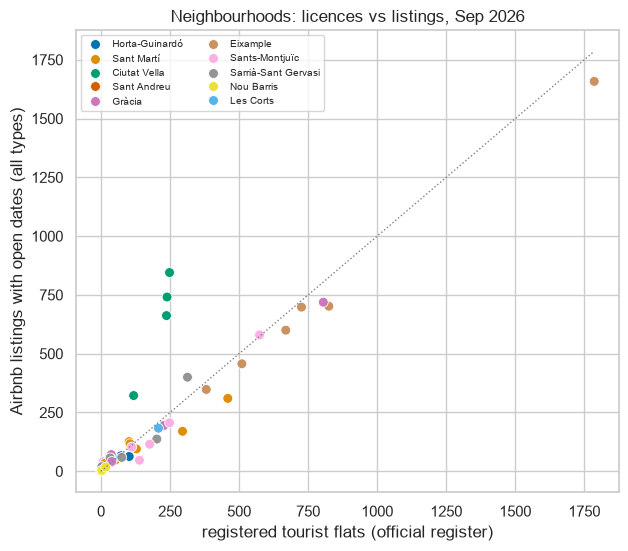

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=by_place, x="registered_huts", y="active_listings", hue="district", ax=ax, s=50)
top = by_place["registered_huts"].max()
ax.plot([0, top], [0, top], color="grey", ls=":", lw=1)
ax.set_xlabel("registered tourist flats (official register)")
ax.set_ylabel("Airbnb listings with open dates (all types)")
ax.set_title("Neighbourhoods: licences vs listings, Sep 2026")
ax.legend(fontsize=7, ncol=2)
fig.savefig(cfg.FIGURES_DIR / "04_register_vs_listings.png", dpi=150, bbox_inches="tight")

Licences and listings sit in the same places (Spearman ρ close to 1).
Neighbourhoods **above** the dotted line have more listings with open dates than
registered flats — almost all in Ciutat Vella. Two features of that district
are consistent with it: over half of its listings ask 31+ nights (54%, vs 32%
in Eixample), a stay length outside the tourist-stay definition, so those
listings are not expected to show a tourist licence; and a third are private
rooms, which cannot hold one. A minimum stay is a setting, not proof of how a
flat is let.

In [6]:
for district in ["Ciutat Vella", "Eixample"]:
    d = latest[latest["neighbourhood_group"] == district]
    print(f"{district:13} listings with open dates={len(d):,}  month-plus={(d['minimum_nights'] >= cfg.STAY_LINE_NIGHTS).mean():.0%}  "
          f"private rooms={(d['room_type'] == 'Private room').mean():.0%}  with licence={d['has_tourist_licence'].mean():.0%}")

Ciutat Vella  listings with open dates=2,570  month-plus=54%  private rooms=32%  with licence=32%
Eixample      listings with open dates=4,463  month-plus=32%  private rooms=24%  with licence=53%


## Rents of new leases, with the policy dates

**What this can show:** how the average rent of *new* leases moved. **What it
cannot show:** why. The average changes when the mix of flats rented
changes (size, area, quality), and many things move rents at once —
interest rates, wages, migration, supply. No causal claim is made.

,quarter_start,avg_rent,new_leases,year_on_year_pct
19,2023-10-01,1178.05,8531,9.3
20,2024-01-01,1193.51,9825,9.8
21,2024-04-01,1131.80,7938,0.7
22,2024-07-01,1133.33,7484,-3.2
23,2024-10-01,1117.39,7656,-5.1
24,2025-01-01,1087.23,7615,-8.9
25,2025-04-01,1135.55,7411,0.3
26,2025-07-01,1153.11,7855,1.7
27,2025-10-01,1160.99,7908,3.9
28,2026-01-01,1137.35,8156,4.6


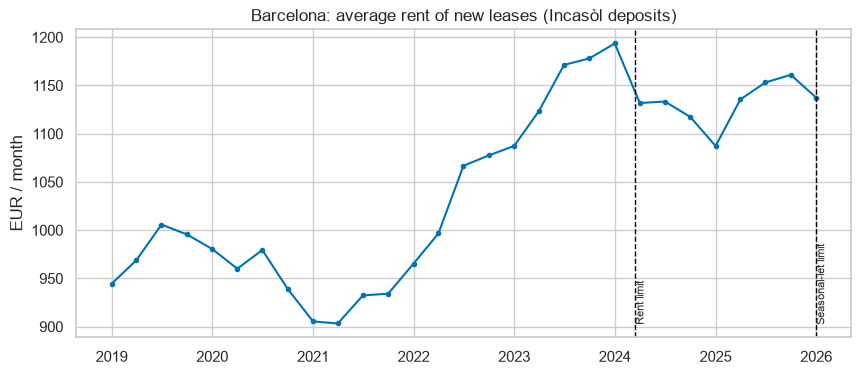

In [7]:
rents = official.load_rents()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(rents["quarter_start"], rents["avg_rent"], marker="o", ms=3, label="average rent (EUR/month)")
ax1.set_ylabel("EUR / month")
for lever in ["rent_cap", "seasonal_rentals"]:
    date = pd.Timestamp(cfg.POLICY_LEVERS[lever]["applies_from"])
    ax1.axvline(date, color="black", ls="--", lw=1)
    ax1.text(date, ax1.get_ylim()[0] + 10, " " + cfg.POLICY_LEVERS[lever]["timeline_label"], fontsize=8, rotation=90, va="bottom")
ax1.set_title("Barcelona: average rent of new leases (Incasòl deposits)")
fig.savefig(cfg.FIGURES_DIR / "04_rents.png", dpi=150, bbox_inches="tight")

rents.assign(year_on_year_pct=(rents["avg_rent"].pct_change(4) * 100).round(1)).tail(10)

## What I found

1. **The register is flat.** 10,514 to 10,730 records in every published
   quarter from 2025 Q1 to 2026 Q3. The 2028 deadline has not started to show,
   and a stable register before a deadline says nothing about whether the
   policy will work.
2. **Most displayed licence numbers exist in the register.** 83.5–86.0% of the
   distinct HUT numbers shown on listings with open dates are in the register
   quarter nearest to each snapshot. The rest cannot be classified from the
   data and are not counted as illegal.
3. **Displayed-number coverage is 37–49%.** 37.0–48.7% of the register's
   numbers are displayed on at least one listing with open dates. This is not
   "the share of licensed flats on Airbnb": a number can be shown by a listing
   that is not that flat, and a flat can be listed without its number.
4. **Licences and listings are in the same places** (Spearman ρ = 0.97 over
   69 neighbourhoods). Ciutat Vella has more listings than licences: 54% of its
   listings with open dates ask 31+ nights, which is consistent with, but does
   not show, a different regime there.
5. **Rents of new leases:** year-on-year growth went from +9.8% in Q1 2024 to
   −8.9% in Q1 2025, then back to +4.6% in Q1 2026 (€1,137 a month). The timing
   overlaps the rent limit, but the data cannot separate it from changes in the
   mix of flats rented or the wider market.
